<a href="https://colab.research.google.com/github/arsenalmorimori/ai-local-rag_arsenal/blob/main/MIMAROPA_Palay_and_Corn_Parts_A_H.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Quarterly Palay and Corn Production in MIMAROPA
**AI 101 · Group 1**  
John Nesty Bautista, Johndel Cuentas, Dorothy Anne Domanico, Arishcia Mae Ellamil, and Aeron Kiel Irasusta

This notebook runs Parts A–H for palay and corn using the same code and fits separate models for each crop. The dataset covers Oriental Mindoro and Palawan. Each crop uses 2011–2022 for training and 2023–2025 for testing.

**In Google Colab** select **Run all**, then upload `mimaropa_data.xlsx` and `mimaropa_climate.csv` together when prompted. The workbook supplies production values and the three lags are derived from it. The climate CSV contains the additional weather and ENSO fields from the earlier group dataset. Keep both input files beside the notebook for a local run with NumPy, pandas, openpyxl, Pillow and IPython.

The worksheet also contains three other MIMAROPA provinces and crop subtypes. This analysis selects the Palay and Corn total series for Oriental Mindoro and Palawan to match the proposed scope and available climate records. It uses 2010 as lag history, 2011–2022 for training, and 2023–2025 for testing. All model parameters are learned from training rows.


## Part A — Problem & Dataset Selection

**What to do:** Choose an open dataset and a target variable to predict. Load it and report its basic shape and structure.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

np.set_printoptions(precision=5, suppress=True, linewidth=160)
WORKBOOK = Path("mimaropa_data.xlsx")
CLIMATE_FILE = Path("mimaropa_climate.csv")
CROPS = ("Palay", "Corn")
PROVINCES = ("Oriental Mindoro", "Palawan")
FEATURES = ["production_lag_1", "production_lag_2", "production_lag_4",
            "temperature_2m_mean", "precipitation_sum",
            "et0_fao_evapotranspiration", "oni_index"]
TARGET = "production"
TEST_START_YEAR = 2023
VARIANCE_TARGET = 0.95

# Colab will request both files if either file is absent from the session.
missing = [file.name for file in (WORKBOOK, CLIMATE_FILE) if not file.is_file()]
if missing:
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError("Place these files alongside the notebook: " + ", ".join(missing)) from error
    print("Upload these files: " + ", ".join(missing))
    files.upload()
    for file in (WORKBOOK, CLIMATE_FILE):
        if not file.is_file():
            raise FileNotFoundError(file.name)

# Read the supplied PSA worksheet as published, including its multilevel headers.
raw = pd.read_excel(WORKBOOK, sheet_name="2E4EVCP0", header=None, engine="openpyxl")
year_headers = raw.iloc[2].ffill()
crop_headers = raw.iloc[:, 0].ffill()
province_labels = raw.iloc[:, 1].astype(str).str.replace(".", "", regex=False).str.strip()
workbook_crops = crop_headers.loc[province_labels.isin(PROVINCES)].dropna().astype(str).str.strip().unique().tolist()
print("Crops:", workbook_crops)
records = []
for r in range(4, len(raw)):
    crop = str(crop_headers.iloc[r]).strip()
    province = str(raw.iat[r, 1]).replace(".", "").strip()
    if crop not in CROPS or province not in PROVINCES:
        continue
    for c in range(2, raw.shape[1]):
        year = int(year_headers.iloc[c])
        quarter = int(str(raw.iat[3, c]).split()[-1])
        records.append((province, year, quarter, crop, raw.iat[r, c]))

production = pd.DataFrame(records, columns=["province", "year", "quarter", "crop", TARGET])
production[TARGET] = pd.to_numeric(production[TARGET], errors="coerce")
production = production.sort_values(["crop", "province", "year", "quarter"]).reset_index(drop=True)
assert not production.duplicated(["province", "year", "quarter", "crop"]).any()
assert np.isfinite(production[TARGET]).all(), "Investigate missing production values in the workbook."
for _, group in production.groupby(["crop", "province"]):
    period = group["year"] * 4 + group["quarter"]
    assert np.all(np.diff(period) == 1), "Quarter gaps would invalidate row-based production lags."

# Derive past-only lags inside each crop/province series using the 2010 history.
for lag in (1, 2, 4):
    production[f"production_lag_{lag}"] = production.groupby(["crop", "province"])[TARGET].shift(lag)
production = production.loc[production["year"].between(2011, 2025)].copy()

# The workbook supplies production only. Climate is an additional source from
# the earlier group dataset, matched to the same province and quarter.
climate_columns = FEATURES[3:]
merge_keys = ["province", "year", "quarter"]
climate = pd.read_csv(CLIMATE_FILE)
assert not climate.duplicated(merge_keys).any()
data = production.merge(climate[merge_keys + climate_columns], on=merge_keys,
                        how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all(), "A production row has no matching climate record."
data = data.drop(columns="_merge")
assert np.isfinite(data[[TARGET, *FEATURES]].to_numpy(dtype=float)).all()
print("Workbook production and lag values retained:", len(data))
print("Climate rows:", len(climate), "matched by province, year and quarter.")
print("Included crops:", CROPS, "| Included provinces:", PROVINCES)

state = {}
for crop in CROPS:
    rows = data[data["crop"] == crop].sort_values(["year", "quarter", "province"]).reset_index(drop=True)
    X_raw = rows[FEATURES].to_numpy(dtype=float)
    y = rows[TARGET].to_numpy(dtype=float)
    assert X_raw.shape == (120, 7)
    state[crop] = {"rows": rows, "X_raw": X_raw, "y": y}
    print(f"\n{crop}: {len(rows)} rows, {X_raw.shape[1]} features")
    print(rows.groupby("province").size().to_string())
    print(rows[["province", "year", "quarter", TARGET, *FEATURES]].head(3).to_string(index=False))


Upload these files: mimaropa_data.xlsx


Saving mimaropa_data.xlsx to mimaropa_data.xlsx
Crops: ['Irrigated Palay', 'Rainfed Palay', 'Palay', 'White Corn', 'Yellow Corn', 'Corn']
Workbook production and lag values retained: 240
Climate rows: 120 matched by province, year and quarter.
Included crops: ('Palay', 'Corn') | Included provinces: ('Oriental Mindoro', 'Palawan')

Palay: 120 rows, 7 features
province
Oriental Mindoro    60
Palawan             60
        province  year  quarter  production  production_lag_1  production_lag_2  production_lag_4  temperature_2m_mean  precipitation_sum  et0_fao_evapotranspiration  oni_index
Oriental Mindoro  2011        1    109859.0          145364.0           25681.0           89139.0            24.183333              843.9                      282.61  -1.166667
         Palawan  2011        1     70970.0          106567.0           23284.0           71128.0            25.997778              843.1                      303.46  -1.166667
Oriental Mindoro  2011        2     72203.0          

### Report answers

**Q1.** What real-world quantity are you trying to predict, and why is it continuous rather than categorical?

Quarterly production is measured in metric tons. It is a continuous quantity, so the supervised task is regression.

**Q2.** Where does your dataset come from? Is it open/public? Provide the source (link or citation).

Production is read directly from the supplied `mimaropa_data.xlsx`, worksheet `2E4EVCP0`, a Philippine Statistics Authority [OpenStat](https://openstat.psa.gov.ph/) export. Production lags are calculated from this workbook. The supplemental `mimaropa_climate.csv` retains the earlier group dataset’s [Philippine Crop Trend Risk Data](https://www.kaggle.com/datasets/josiahdanielcatabay/cropforecast-ph-crop-trend-risk-2010-2025) weather and ENSO fields, matched by province and quarter.

**Q3.** How many samples (n) and how many features (p) does your dataset have?

The merged dataset has 240 rows. This crop contributes n = 120 rows and p = 7 predictors, with 60 quarters for each of two provinces.

**Q4.** Before doing any analysis, which features do you expect to be most predictive, and why?

Lag 4 should be especially useful because the same quarter last year captures recurring harvest seasons. Shorter lags capture recent production, and climate variables capture growing conditions.

## Part B — Matrices

**What to do:** Represent your dataset as a design matrix X ∈ ℝⁿˣᵖ. Compute the product XᵀX.

In [ ]:
for crop, result in state.items():
    X = np.asarray(result["X_raw"], dtype=float)
    X_transpose = X.T
    XtX = X_transpose @ X
    result.update(X=X, XtX=XtX)
    i, j = 0, 1
    row = X[:1]
    X_plus = np.vstack([X, row])
    assert np.allclose(XtX, XtX.T)
    assert np.isclose(XtX[i, j], X[:, i] @ X[:, j])
    assert np.allclose(X_plus.T @ X_plus, XtX + row.T @ row)
    print(f"\n{crop}: X {X.shape}, X.T {X_transpose.shape}, X.T @ X {XtX.shape}")
    print(f"Lag 1 × lag 2: {XtX[i, j]:.6e} t²")
    print(pd.DataFrame(XtX, index=FEATURES, columns=FEATURES).to_string(float_format=lambda a: f"{a:.4e}"))


Palay: X (120, 7), X.T (7, 120), X.T @ X (7, 7)
Lag 1 × lag 2: 9.694133e+11 t²
                            production_lag_1  production_lag_2  production_lag_4  temperature_2m_mean  precipitation_sum  et0_fao_evapotranspiration   oni_index
production_lag_1                  1.3172e+12        9.6941e+11        9.5992e+11           2.9260e+08         1.0092e+10                  3.7003e+09 -3.0441e+05
production_lag_2                  9.6941e+11        1.3106e+12        9.1027e+11           2.9603e+08         9.5067e+09                  3.7761e+09 -1.7218e+05
production_lag_4                  9.5992e+11        9.1027e+11        1.2895e+12           2.8596e+08         1.2268e+10                  3.4163e+09 -3.4995e+05
temperature_2m_mean               2.9260e+08        2.9603e+08        2.8596e+08           8.4756e+04         3.0018e+06                  1.0514e+06 -5.8543e+01
precipitation_sum                 1.0092e+10        9.5067e+09        1.2268e+10           3.0018e+06         1.980

### Report answers

**Q5.** What are n and p for your dataset? What does each row of X represent? What does each column represent?

n = 120 and p = 7 for this crop. Each row is a province-quarter. Columns are three production lags, temperature, precipitation, reference evapotranspiration and ONI. The target y holds production in metric tons.

**Q6.** What are the dimensions of XᵀX, and why is that shape useful for the steps that come later?

XᵀX is 7 × 7. Its size depends on the number of features, and the square matrix supports determinant and normal-equation calculations.

**Q7.** Pick one single off-diagonal entry of XᵀX and explain, in words, what it measures about your two corresponding features.

**Palay.** The lag-1 by lag-2 Gram entry is 9.694133e+11 t². It sums the products of the two observed lag columns over all 120 rows. This is an uncentered dot product.

**Corn.** The lag-1 by lag-2 Gram entry is 1.375136e+09 t². It sums the products of the two observed lag columns over all 120 rows. This is an uncentered dot product.

**Q8.** If you added one new sample to your dataset, how would X change? Would XᵀX change in the same simple way? Explain.

A new 1 × 7 row x makes X 121 × 7. The Gram matrix stays 7 × 7 and gains xᵀx.

## Part C — Vector Spaces

**What to do:** Compute the rank of X. Determine whether its columns are linearly independent.

In [ ]:
for crop, result in state.items():
    X = result["X"]
    train_mask = result["rows"]["year"].to_numpy() < TEST_START_YEAR
    rank_X = np.linalg.matrix_rank(X)
    dependent = np.column_stack([X, (X[:, 0] + X[:, 1]) / 2])
    result.update(rank_X=rank_X, train_mask=train_mask)
    print(f"{crop}: rank {rank_X} of {X.shape[1]}, training rank {np.linalg.matrix_rank(X[train_mask])}")
    print(f"With a dependent lag column: rank {np.linalg.matrix_rank(dependent)} of {dependent.shape[1]}")

Palay: rank 7 of 7, training rank 7
With a dependent lag column: rank 7 of 8
Corn: rank 7 of 7, training rank 7
With a dependent lag column: rank 7 of 8


### Report answers

**Q9.** What is the dimension of the feature space your data lives in (before any reduction)?

The feature space is ℝ⁷. Each feature column is a vector in ℝ¹²⁰.

**Q10.** What is rank(X)? Is it equal to the number of features p? If not, what does that tell you about your features?

Rank(X) is 7 and equals p. The seven columns are linearly independent at NumPy’s default SVD tolerance. The raw training rows also have rank 7.

**Q11.** In your own words, what is the column space of X, and why does it matter for what predictions your regression model can possibly make?

The column space contains all combinations Xβ. Least squares projects the target onto the column space of the actual fit design, including the intercept when used.

**Q12.** Describe what a linearly dependent feature would look like in your own dataset (a real or hypothetical example), and why it would be a problem for your model.

Appending the average of lag 1 and lag 2 creates an exact linear combination. The augmented design has eight columns but rank seven. This makes its Gram matrix singular and leaves coefficients non-unique.

## Part D — Linear Transformations

**What to do:** Define at least one linear transformation (e.g., standardization, normalization, or a projection) and apply it to your data.

In [ ]:
for crop, result in state.items():
    X, y = result["X"], result["y"]
    train_mask = result["train_mask"]
    test_mask = ~train_mask
    mu = X[train_mask].mean(axis=0)
    raw_sigma = X[train_mask].std(axis=0)
    sigma = np.where(raw_sigma == 0, 1.0, raw_sigma)
    S = np.diag(1.0 / sigma)
    X_scaled = (X - mu) @ S
    X_train, X_test = X_scaled[train_mask], X_scaled[test_mask]
    assert np.allclose(X_scaled @ np.diag(sigma) + mu, X)
    assert np.allclose(X_train.mean(axis=0), 0)
    result.update(mu=mu, sigma=sigma, S=S, X_train=X_train, X_test=X_test,
                  y_train=y[train_mask], y_test=y[test_mask], X_test_raw=X[test_mask],
                  test_rows=result["rows"].loc[test_mask].reset_index(drop=True))
    print(f"\n{crop}: training {X_train.shape}, held out {X_test.shape}")
    print("Zero-variance columns:", [name for name, sd in zip(FEATURES, raw_sigma) if sd == 0])
    print(pd.DataFrame({"Train mean": mu, "Train std": raw_sigma, "S diagonal": S.diagonal(),
                        "Raw example": X[0], "Scaled example": X_scaled[0]}, index=FEATURES).to_string())

    idx = 0  # row index within each crop's test set

    x_before = result["X_test_raw"][idx]
    x_after = result["X_test"][idx]
    print(f"\n=== {crop} (test sample {idx}) ===")
    print("Before:", x_before)
    print("After: ", x_after)
    print(pd.DataFrame({"Before": x_before, "After": x_after}, index=FEATURES).to_string())


Palay: training (96, 7), held out (24, 7)
Zero-variance columns: []
                              Train mean     Train std  S diagonal    Raw example  Scaled example
production_lag_1            90018.814792  48986.759724    0.000020  145364.000000        1.129799
production_lag_2            89303.171458  49423.123448    0.000020   25681.000000       -1.287296
production_lag_4            87772.356250  50148.733274    0.000020   89139.000000        0.027252
temperature_2m_mean            26.544831      0.904595    1.105467      24.183333       -2.610558
precipitation_sum             954.025000    883.731657    0.001132     843.900000       -0.124614
et0_fao_evapotranspiration    330.260104     44.144842    0.022653     282.610000       -1.079404
oni_index                      -0.099306      0.814410    1.227883      -1.166667       -1.310595

=== Palay (test sample 0) ===
Before: [156729.53     23646.87     88416.26        24.99111   2677.1        270.79        -0.4    ]
After:  [ 1.361

### Report answers

**Q13.** Which linear transformation did you apply to your data? Write its matrix representation M such that T(x) = Mx.

For a row x, transform it with (x − μ)S, where S = diag(1/σ₁,…,1/σ₇). The train-derived mean subtraction is affine in the raw input. Multiplication by S on the centered row is linear.

**Q14.** Using one actual data point from your dataset, show the before vector x and the after vector T(x) = Mx.

**Palay.** The first sorted observation has raw features [1.4536e+05, 25681, 89139, 24.183, 843.9, 282.61, -1.1667] and training-scaled features [1.1298, -1.2873, 0.027252, -2.6106, -0.12461, -1.0794, -1.3106] in the same column order.

**Corn.** The first sorted observation has raw features [108, 4, 6, 24.183, 843.9, 282.61, -1.1667] and training-scaled features [-0.96678, -0.99304, -0.9649, -2.6106, -0.12461, -1.0794, -1.3106] in the same column order.

**Q15.** Is your transformation invertible? How do you know, and why would invertibility matter if you wanted to convert a prediction back to original units?

All seven scaling factors have nonzero denominators. Recover x as transformed_row S⁻¹ + μ. The target was never scaled, so model output is already in metric tons.

**Q16.** Would your transformation's matrix change if computed from a different subset of your data (e.g., a different train/test split)? What does that imply about how you must apply it consistently to both training and test data?

A different training subset can give different means and deviations. Fit once on 2011–2022 and reuse them unchanged on 2023–2025 and on future inputs.

## Part E — Determinants

**What to do:** Compute det(XᵀX) on your training data (after your Part D transformation) before attempting to invert it.

In [ ]:
for crop, result in state.items():
    X_train = result["X_train"]
    XtX_train = X_train.T @ X_train
    determinant = np.linalg.det(XtX_train)
    condition = np.linalg.cond(XtX_train)
    rank = np.linalg.matrix_rank(XtX_train)
    result.update(XtX_train=XtX_train, determinant=determinant, condition=condition)
    print(f"{crop}: det = {determinant:.8e}, condition number = {condition:.6f}, rank = {rank}")
    print("Invertible:", rank == XtX_train.shape[0])

Palay: det = 3.40498297e+12, condition number = 27.561186, rank = 7
Invertible: True
Corn: det = 8.80678611e+12, condition number = 18.941387, rank = 7
Invertible: True


### Report answers

**Q17.** What is det(XᵀX) for your training data?

**Palay.** The training Gram determinant after scaling is 3.40498297e+12.

**Corn.** The training Gram determinant after scaling is 8.80678611e+12.

**Q18.** Based on that value, is XᵀX invertible? If it were numerically singular, what would you do instead?

The standardized training Gram matrix has rank seven and is invertible. For a singular fit design, use SVD least squares or a pseudoinverse to obtain a minimum-norm coefficient solution.

**Q19.** Describe a realistic situation in your own dataset (e.g., two nearly duplicate features) that could push this determinant close to zero.

An added average of lag 1 and lag 2 would make the determinant zero because it duplicates a combination of two existing columns. Near-duplicate weather variables could make the system less stable.

**Q20.** Look up or compute the condition number of XᵀX. How does a large condition number relate to the determinant, and what does it suggest about the stability of your model?

**Palay.** The 2-norm condition number is 27.5612. A large condition number indicates sensitivity to perturbations. Determinant size depends on scale, so use condition number and rank to diagnose stability.

**Corn.** The 2-norm condition number is 18.9414. A large condition number indicates sensitivity to perturbations. Determinant size depends on scale, so use condition number and rank to diagnose stability.

## Part F — Eigenvalues & Eigenvectors

**What to do:** Compute the eigenvalues and eigenvectors of a matrix relevant to your data (e.g., the covariance matrix of your standardized training features).

In [ ]:
def show(image):
    from IPython.display import display
    display(image)


import numpy as np
from PIL import Image, ImageDraw, ImageFont

def plot(title, x, y, xlabel, ylabel, mode="scatter", diagonal=False, threshold=None, color_values=None):
    image = Image.new("RGB", (880, 500), "white")
    draw = ImageDraw.Draw(image)
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", 18)
        heading = ImageFont.truetype("DejaVuSans.ttf", 24)
    except OSError:
        font = ImageFont.load_default(size=18)
        heading = ImageFont.load_default(size=24)
    ink, blue = "#20334a", "#196e75"
    left, top, right, bottom = 108, 88, 835, 420
    xmin, xmax, ymin, ymax = np.min(x), np.max(x), np.min(y), np.max(y)
    if mode == "line":
        ymin = 0
    if threshold is not None:
        ymax = 100
    if diagonal:
        xmin = ymin = min(xmin, ymin)
        xmax = ymax = max(xmax, ymax)
    def point(a, b):
        return (left + (a-xmin)/(xmax-xmin)*(right-left),
                bottom - (b-ymin)/(ymax-ymin)*(bottom-top))
    draw.text((left, 12), title, font=heading, fill=ink)
    for tick in np.linspace(ymin, ymax, 6):
        _, yp = point(xmin, tick)
        draw.line((left, yp, right, yp), fill="#e1e7eb")
        draw.text((left-10, yp), f"{tick:,.2f}".rstrip("0").rstrip("."), anchor="rm", font=font, fill=ink)
    xticks = x if mode == "line" else np.linspace(xmin, xmax, 6)
    for tick in xticks:
        xp, _ = point(tick, ymin)
        label = f"{tick:,.0f}" if mode == "line" or diagonal else f"{tick:.1f}"
        draw.text((xp, bottom+9), label, anchor="mt", font=font, fill=ink)
    draw.line((left, top, left, bottom, right, bottom), fill=ink, width=2)
    if diagonal:
        draw.line([point(xmin, ymin), point(xmax, ymax)], fill="#a8482c", width=2)
    if threshold is not None:
        draw.line([point(xmin, threshold), point(xmax, threshold)], fill="#a8482c", width=2)
        draw.text((right, top+24), "95% threshold", anchor="rt", font=font, fill="#a8482c")
    points = [point(a,b) for a,b in zip(x,y)]
    if mode == "line":
        draw.line(points, fill=blue, width=3)
    for idx,(px,py) in enumerate(points):
        marker = blue
        if color_values is not None:
            fraction = np.sqrt(max(0, color_values[idx]) / max(color_values))
            marker = tuple(int(lo + fraction*(hi-lo)) for lo,hi in zip((57,149,160),(190,73,31)))
        draw.ellipse((px-3, py-3, px+3, py+3), fill=marker)
    draw.text((left, top-9), ylabel, anchor="lb", font=font, fill=ink)
    draw.text(((left+right)/2, bottom+38), xlabel, anchor="mt", font=font, fill=ink)
    if color_values is not None:
        draw.text((left, 480), f"Production color scale: teal = 0 t; orange = {max(color_values):,.0f} t", font=font, fill=ink)
    return image


Palay: covariance (7, 7), eigenpair residual 1.938e-15
v1: [-0.02544  0.37149 -0.42935  0.47265 -0.37695  0.52739  0.18272] | lambda: 3.0035714960083473
Cv1: [-0.07642  1.11579 -1.28959  1.41963 -1.13219  1.58404  0.5488 ] | lambda*v1: [-0.07642  1.11579 -1.28959  1.41963 -1.13219  1.58404  0.5488 ]
 PC  Eigenvalue  Explained (%)  Cumulative (%)
  1     3.00357       42.46120        42.46120
  2     1.38451       19.57265        62.03386
  3     1.05714       14.94465        76.97851
  4     0.71518       10.11041        87.08892
  5     0.54151        7.65532        94.74424
  6     0.26280        3.71514        98.45938
  7     0.10898        1.54062       100.00000
Leading loadings:
et0_fao_evapotranspiration    0.52739
temperature_2m_mean           0.47265
production_lag_4             -0.42935
precipitation_sum            -0.37695
production_lag_2              0.37149
oni_index                     0.18272
production_lag_1             -0.02544


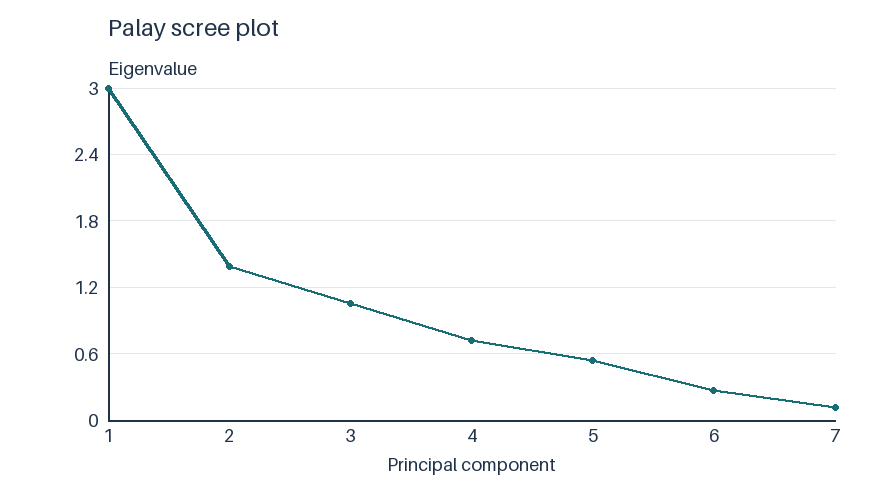

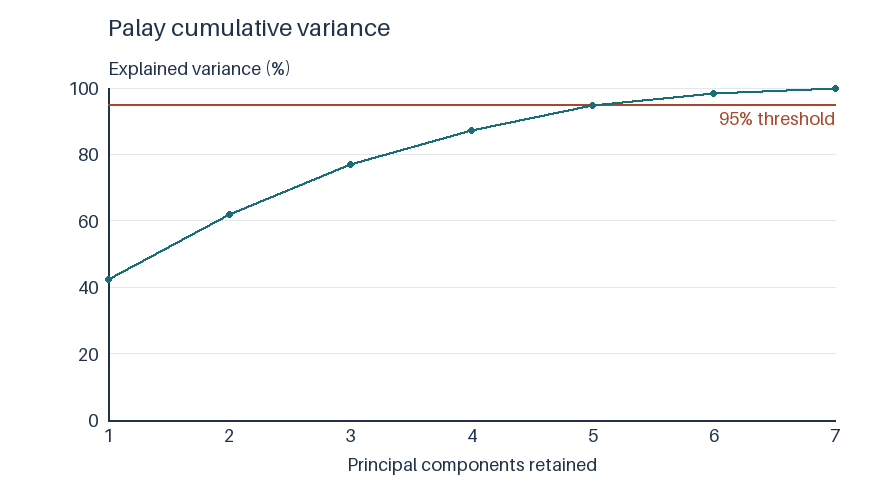


Corn: covariance (7, 7), eigenpair residual 8.812e-16
v1: [-0.1989  -0.40208 -0.22414 -0.41637  0.48998 -0.52199 -0.25024] | lambda: 2.536620921683368
Cv1: [-0.50453 -1.01993 -0.56856 -1.05618  1.24288 -1.32408 -0.63477] | lambda*v1: [-0.50453 -1.01993 -0.56856 -1.05618  1.24288 -1.32408 -0.63477]
 PC  Eigenvalue  Explained (%)  Cumulative (%)
  1     2.53662       35.85997        35.85997
  2     1.53644       21.72053        57.58049
  3     0.91703       12.96399        70.54448
  4     0.74483       10.52966        81.07414
  5     0.69813        9.86938        90.94352
  6     0.50671        7.16327        98.10679
  7     0.13392        1.89321       100.00000
Leading loadings:
et0_fao_evapotranspiration   -0.52199
precipitation_sum             0.48998
temperature_2m_mean          -0.41637
production_lag_2             -0.40208
oni_index                    -0.25024
production_lag_4             -0.22414
production_lag_1             -0.19890


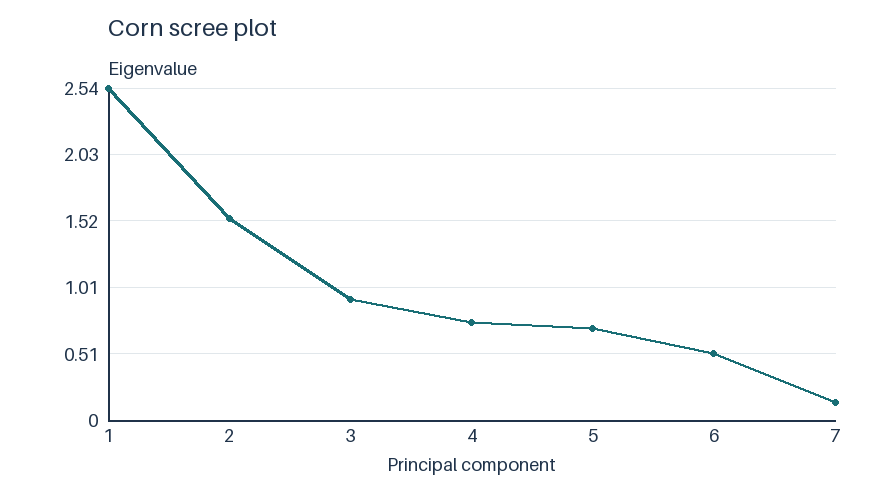

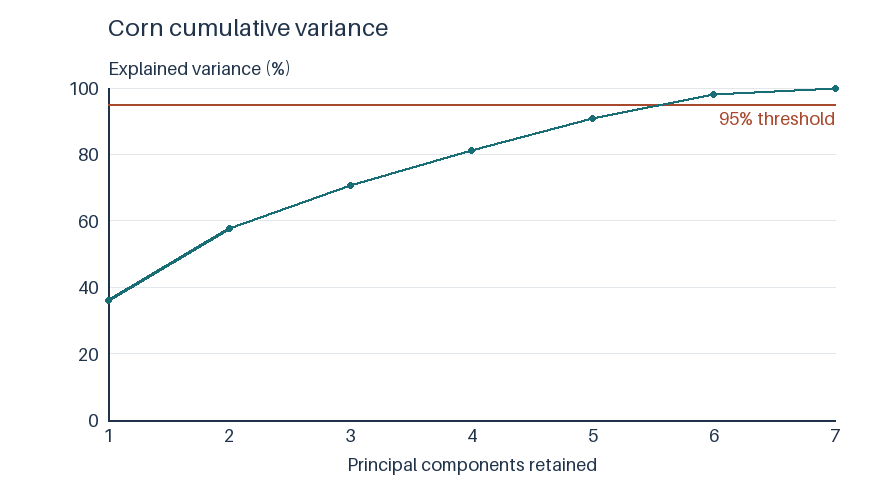

In [ ]:
for crop, result in state.items():
    X_train = result["X_train"]
    pca_mean = X_train.mean(axis=0)
    C = np.cov(X_train, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(C)
    order = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    v1, lam1 = eigvecs[:, 0], eigvals[0]
    residual = np.linalg.norm(C @ v1 - lam1 * v1)
    assert np.allclose(C, C.T) and residual < 1e-12
    explained = eigvals / eigvals.sum()
    cumulative = explained.cumsum()
    components = np.arange(1, len(eigvals) + 1)
    result.update(C=C, eigvals=eigvals, eigvecs=eigvecs, pca_mean=pca_mean, cumulative=cumulative)
    print(f"\n{crop}: covariance {C.shape}, eigenpair residual {residual:.3e}")
    print("v1:", v1, "| lambda:", lam1)
    print("Cv1:", C @ v1, "| lambda*v1:", lam1 * v1)
    print(pd.DataFrame({"PC": components, "Eigenvalue": eigvals, "Explained (%)": 100 * explained,
                        "Cumulative (%)": 100 * cumulative}).round(5).to_string(index=False))
    print("Leading loadings:")
    print(pd.Series(v1, index=FEATURES).sort_values(key=abs, ascending=False).round(5).to_string())
    show(plot(f"{crop} scree plot", components, eigvals, "Principal component", "Eigenvalue", mode="line"))
    show(plot(f"{crop} cumulative variance", components, 100 * cumulative, "Principal components retained",
              "Explained variance (%)", mode="line", threshold=100 * VARIANCE_TARGET))

### Report answers

**Q21.** Which matrix did you decompose, and why is it symmetric? Why does symmetry matter for this decomposition?

We decomposed the symmetric 7 × 7 sample covariance of scaled training predictors. Symmetry gives a real spectrum and an orthonormal eigenbasis.

**Q22.** List your eigenvalues from largest to smallest. What percentage of total variance does the single largest eigenvalue explain?

**Palay.** The descending eigenvalues are [3.0036, 1.3845, 1.0571, 0.71518, 0.54151, 0.2628, 0.10898]. PC1 explains 42.46% of total training variance.

**Corn.** The descending eigenvalues are [2.5366, 1.5364, 0.91703, 0.74483, 0.69813, 0.50671, 0.13392]. PC1 explains 35.86% of total training variance.

**Q23.** Verify numerically that Cv = λv for at least one eigenpair. Report the vectors/values you used and the resulting numerical error.

**Palay.** Using λ = 3.003571 and v = [-0.025442, 0.37149, -0.42935, 0.47265, -0.37695, 0.52739, 0.18272], the L2 norm of Cv − λv is 1.938e-15.

**Corn.** Using λ = 2.536621 and v = [-0.1989, -0.40208, -0.22414, -0.41637, 0.48998, -0.52199, -0.25024], the L2 norm of Cv − λv is 8.812e-16.

**Q24.** Look at the eigenvector associated with the largest eigenvalue. Which original features contribute most strongly to it, and what does that tell you about your data?

**Palay.** Largest absolute loadings are et0_fao_evapotranspiration (+0.5274), temperature_2m_mean (+0.4726), production_lag_4 (-0.4294). These features drive the dominant direction of feature variation. The sign can flip with the eigenvector orientation.

**Corn.** Largest absolute loadings are et0_fao_evapotranspiration (-0.5220), precipitation_sum (+0.4900), temperature_2m_mean (-0.4164). These features drive the dominant direction of feature variation. The sign can flip with the eigenvector orientation.

## Part G — Diagonalization

**What to do:** Diagonalize your matrix from Part F (C = VΛV⁻¹, or C = VΛVᵀ if symmetric) and use it to reduce dimensionality.


Palay: V (7, 7), Λ (7, 7), reconstruction error 2.991e-15
k = 6, retained variance = 98.4594%, PCA shapes (96, 6) and (24, 6)


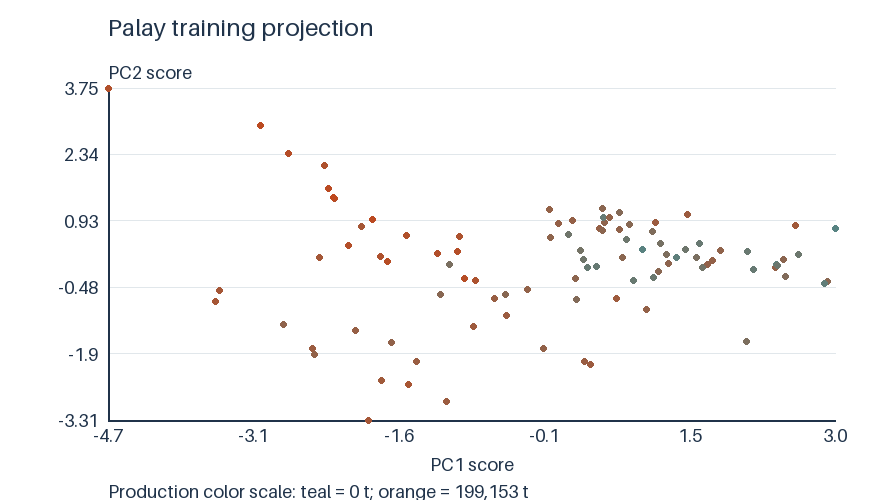


Corn: V (7, 7), Λ (7, 7), reconstruction error 3.392e-15
k = 6, retained variance = 98.1068%, PCA shapes (96, 6) and (24, 6)


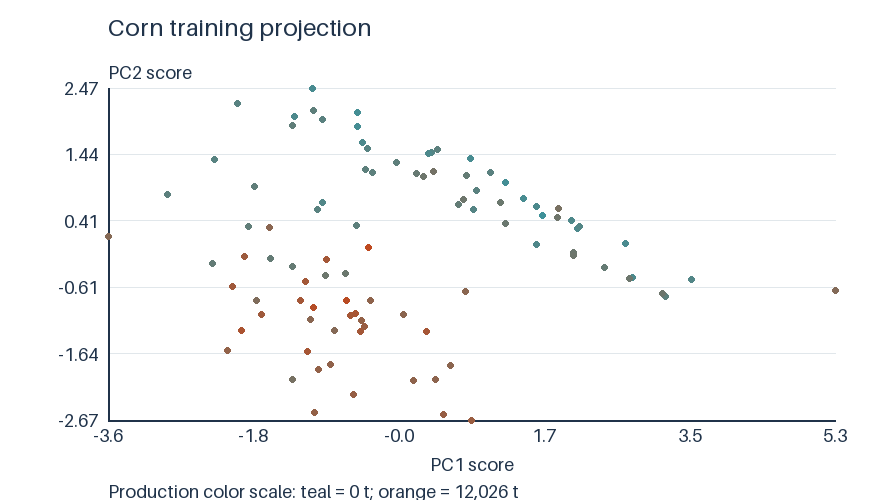

In [ ]:
for crop, result in state.items():
    V = result["eigvecs"]
    Lambda = np.diag(result["eigvals"])
    C = result["C"]
    reconstruction_error = np.linalg.norm(C - V @ Lambda @ V.T, ord="fro")
    assert np.allclose(V.T @ V, np.eye(V.shape[1])) and np.allclose(C, V @ Lambda @ V.T)
    cumulative = result["cumulative"]
    k = int(np.searchsorted(cumulative, VARIANCE_TARGET)) + 1
    V_k = V[:, :k]
    Z_train = (result["X_train"] - result["pca_mean"]) @ V_k
    Z_test = (result["X_test"] - result["pca_mean"]) @ V_k
    result.update(k=k, V_k=V_k, Z_train=Z_train, Z_test=Z_test)
    print(f"\n{crop}: V {V.shape}, Λ {Lambda.shape}, reconstruction error {reconstruction_error:.3e}")
    print(f"k = {k}, retained variance = {100 * cumulative[k-1]:.4f}%, PCA shapes {Z_train.shape} and {Z_test.shape}")
    show(plot(f"{crop} training projection", Z_train[:, 0], Z_train[:, 1],
              "PC1 score", "PC2 score", color_values=result["y_train"]))

### Report answers

**Q25.** Write your diagonalization in the form C = VΛV⁻¹ (or VΛVᵀ). What are the dimensions of V and Λ?

C = VΛVᵀ. Both V and Λ are 7 × 7, and VᵀV = I.

**Q26.** How did you verify, numerically, that your diagonalization is correct?

**Palay.** The code checks VᵀV against identity and reconstructs C. The Frobenius residual is 2.991e-15.

**Corn.** The code checks VᵀV against identity and reconstructs C. The Frobenius residual is 3.392e-15.

**Q27.** How many components did you keep to explain at least 95% of the variance? Why did you choose that threshold?

**Palay.** 6 components retain 98.46% of training variance. This is the smallest count meeting the prespecified 95% threshold.

**Corn.** 6 components retain 98.11% of training variance. This is the smallest count meeting the prespecified 95% threshold.

**Q28.** What is lost — mathematically and practically — when you reduce dimensionality this way? Give a concrete, specific answer for your data.

**Palay.** Projection discards 1.54% of training feature variance and removes the exact ability to reconstruct every row. A low-variance direction can still carry information about production.

**Corn.** Projection discards 1.89% of training feature variance and removes the exact ability to reconstruct every row. A low-variance direction can still carry information about production.

## Part H — Building & Evaluating the Regression Model

**What to do:** Fit at least two model variants (e.g., using all features vs. using your reduced eigenbasis from Part G). Evaluate both on held-out test data.


Palay inference example: Oriental Mindoro, 2023 Q1
Raw: [156729.53     23646.87     88416.26        24.99111   2677.1        270.79        -0.4    ]
Scaled: [ 1.36181 -1.32845  0.01284 -1.71759  1.94977 -1.34716 -0.36922]
PCA scores: [-2.85837 -1.02775 -0.78555  0.67058 -1.38453  0.21795]
Full design row: [ 1.       1.36181 -1.32845  0.01284 -1.71759  1.94977 -1.34716 -0.36922]
PCA design row: [ 1.      -2.85837 -1.02775 -0.78555  0.67058 -1.38453  0.21795]
Actual 77,858.92 t | Full 93,875.68 t | PCA 93,112.10 t
Oriental Mindoro: Full RMSE 11,964.14 t, PCA RMSE 13,121.18 t
Palawan: Full RMSE 14,364.41 t, PCA RMSE 13,134.61 t


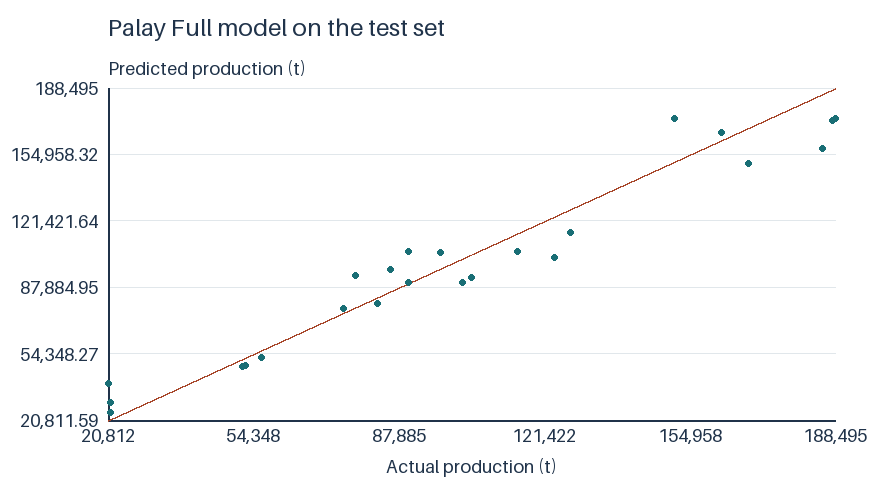

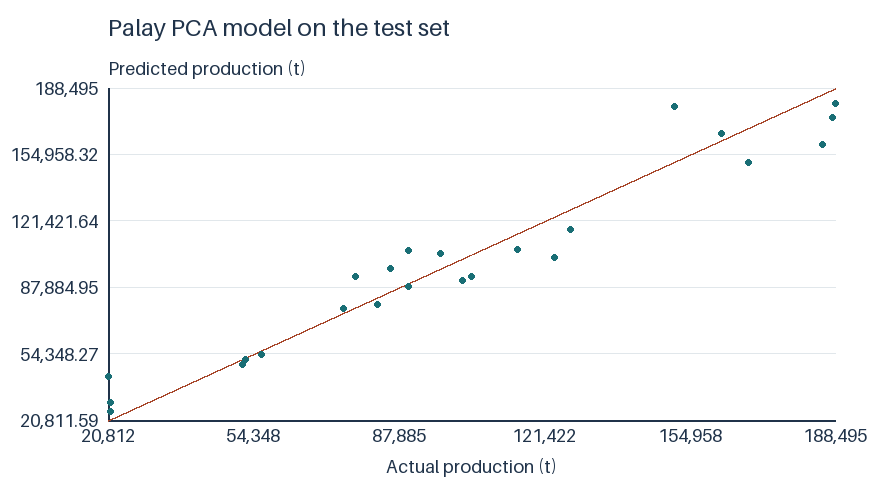


Corn inference example: Oriental Mindoro, 2023 Q1
Raw: [1359.17    1238.66     355.94      24.99111 2677.1      270.79      -0.4    ]
Scaled: [-0.55037 -0.57801 -0.84787 -1.71759  1.94977 -1.34716 -0.36922]
PCA scores: [ 2.998   -0.10969  0.29738  0.0365  -0.3585  -0.88163]
Full design row: [ 1.      -0.55037 -0.57801 -0.84787 -1.71759  1.94977 -1.34716 -0.36922]
PCA design row: [ 1.       2.998   -0.10969  0.29738  0.0365  -0.3585  -0.88163]
Actual 900.51 t | Full 703.94 t | PCA 621.20 t
Oriental Mindoro: Full RMSE 735.26 t, PCA RMSE 963.98 t
Palawan: Full RMSE 508.22 t, PCA RMSE 685.06 t


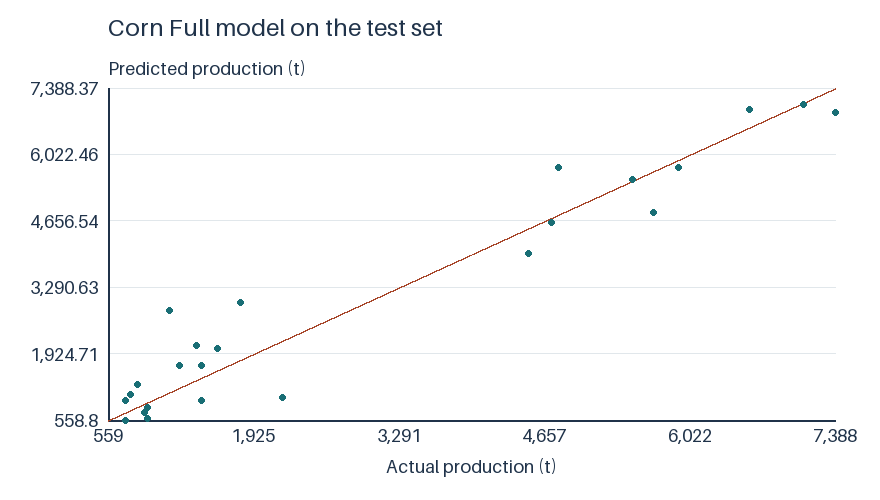

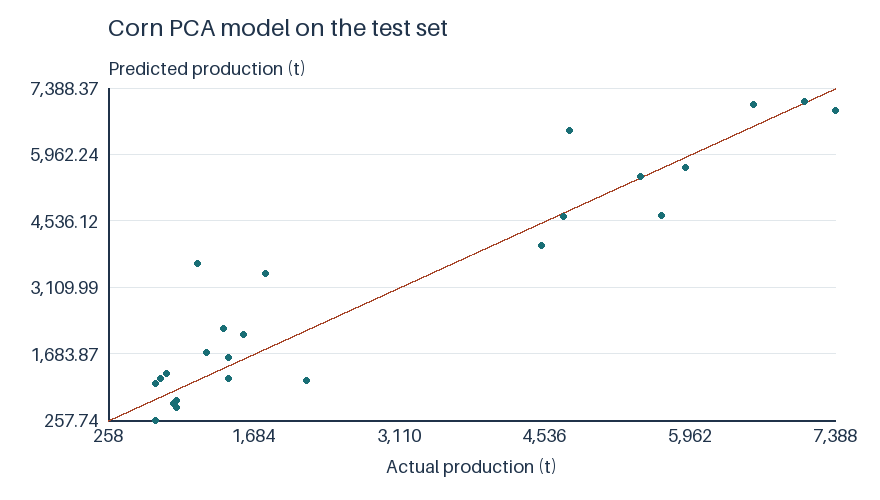


Test results
 Crop     Model  Predictors Test RMSE (t) Test R²
Palay      Full           7     13,218.87  0.9329
Palay       PCA           6     13,127.90  0.9338
Palay Lags only           3      9,498.84  0.9654
 Corn      Full           7        632.02  0.9264
 Corn       PCA           6        836.23  0.8711
 Corn Lags only           3        440.71  0.9642


In [ ]:
def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])

def fit_normal_equation(X, y):
    A = add_intercept(X)
    gram = A.T @ A
    rhs = A.T @ y
    if np.linalg.matrix_rank(gram) == gram.shape[0]:
        return np.linalg.solve(gram, rhs)
    return np.linalg.pinv(gram) @ rhs

def predict(X, beta):
    return add_intercept(X) @ beta

def rmse(y, predicted):
    return np.sqrt(np.mean((y - predicted) ** 2))

def r2_score(y, predicted):
    return 1 - np.sum((y - predicted) ** 2) / np.sum((y - y.mean()) ** 2)

summary = []
for crop, result in state.items():
    X_train, X_test = result["X_train"], result["X_test"]
    Z_train, Z_test = result["Z_train"], result["Z_test"]
    y_train, y_test = result["y_train"], result["y_test"]
    designs = {
        "Full": (X_train, X_test),
        "PCA": (Z_train, Z_test),
        "Lags only": (X_train[:, :3], X_test[:, :3]),
    }
    weights, predictions = {}, {}
    for name, (training, testing) in designs.items():
        weights[name] = fit_normal_equation(training, y_train)
        predictions[name] = predict(testing, weights[name])
        summary.append((crop, name, training.shape[1], rmse(y_test, predictions[name]),
                        r2_score(y_test, predictions[name])))

    reference, *_ = np.linalg.lstsq(add_intercept(X_train), y_train, rcond=None)
    assert np.allclose(predictions["Full"], predict(X_test, reference))
    result.update(weights=weights, predictions=predictions)

    first = result["test_rows"].iloc[0]
    print(f"\n{crop} inference example: {first['province']}, {first['year']} Q{first['quarter']}")
    print("Raw:", result["X_test_raw"][0])
    print("Scaled:", X_test[0])
    print("PCA scores:", Z_test[0])
    print("Full design row:", add_intercept(X_test)[0])
    print("PCA design row:", add_intercept(Z_test)[0])
    print(f"Actual {y_test[0]:,.2f} t | Full {predictions['Full'][0]:,.2f} t | PCA {predictions['PCA'][0]:,.2f} t")
    for province in result["test_rows"]["province"].unique():
        mask = result["test_rows"]["province"].to_numpy() == province
        print(f"{province}: Full RMSE {rmse(y_test[mask], predictions['Full'][mask]):,.2f} t, "
              f"PCA RMSE {rmse(y_test[mask], predictions['PCA'][mask]):,.2f} t")
    for name in ("Full", "PCA"):
        show(plot(f"{crop} {name} model on the test set", y_test, predictions[name],
                  "Actual production (t)", "Predicted production (t)", diagonal=True))

comparison = pd.DataFrame(summary, columns=["Crop", "Model", "Predictors", "Test RMSE (t)", "Test R²"])
print("\nTest results")
print(comparison.to_string(index=False, formatters={"Test RMSE (t)": lambda x: f"{x:,.2f}",
                                                    "Test R²": lambda x: f"{x:.4f}"}))

### Report answers

**Q29.** Write the closed-form equation you used to fit your regression coefficients. What single linear algebra operation is at the core of it?

For the intercept-augmented design A, solve AᵀAβ = Aᵀy. The equivalent closed form is β = (AᵀA)⁻¹Aᵀy for a full-rank design. The implementation solves the system directly and uses a Moore–Penrose pseudoinverse if the Gram matrix is singular.

**Q30.** Report at least two evaluation metrics (e.g., R², RMSE, MAE) on the test set for each model variant.

**Palay.** Full: RMSE 13,218.87 t and R² 0.9329. PCA: RMSE 13,127.90 t and R² 0.9338. Lags only: RMSE 9,498.84 t and R² 0.9654.

**Corn.** Full: RMSE 632.02 t and R² 0.9264. PCA: RMSE 836.23 t and R² 0.8711. Lags only: RMSE 440.71 t and R² 0.9642.

**Q31.** Which model variant performed better? Connect that result back to one specific earlier finding (e.g., rank, eigenvalues, condition number).

**Palay.** The PCA model has lower test RMSE between the two required models. PCA retains the largest feature-variance directions, which need not be the subset most useful for predicting the target. Compare the lags-only row to the full row for the climate contribution.

**Corn.** The full model has lower test RMSE between the two required models. PCA retains the largest feature-variance directions, which need not be the subset most useful for predicting the target. Compare the lags-only row to the full row for the climate contribution.

**Q32.** Walk through, step-by-step, every matrix operation your pipeline would perform to turn one brand-new sample's raw features into a final prediction.

**Palay.** For Oriental Mindoro, 2023 Q1, scale the raw row (7 inputs) using training μ and S. For PCA, subtract the PCA training center, then project with V_k to get 6 scores. Prepend 1 and take the dot product with the relevant fitted β. Full and PCA estimates are 93,875.68 and 93,112.10 t. The prior code cell displays the intermediate vectors.

**Corn.** For Oriental Mindoro, 2023 Q1, scale the raw row (7 inputs) using training μ and S. For PCA, subtract the PCA training center, then project with V_k to get 6 scores. Prepend 1 and take the dot product with the relevant fitted β. Full and PCA estimates are 703.94 and 621.20 t. The prior code cell displays the intermediate vectors.

Both crops use identical preprocessing and estimation code. Each model learns its parameters from its own training rows. In the verified 2023–2025 holdout, the lag-only model had the lowest RMSE for each crop. The climate block uses observed same-quarter conditions, so these results describe a historical estimation task.